Most of the data science I see around marketplaces answers one of four
questions. What happened (descriptive statistics), what is associated with what
(regression), what will happen to this unit (prediction, machine learning), and
what is the effect of this change (causal inference, experiments). That toolkit
is powerful, and the last one in particular has become the backbone of decision
making in tech companies.

Yet a team can have all four in place and still not be able to answer a question
an executive asks routinely: *why does the marketplace behave the way it does,
and what happens if we push here for two years?* An A/B test tells us what the
world looks like two weeks after a change, holding almost everything else fixed.
It does not tell us how the change propagates through supply, matching,
reputation, and churn, each of which moves on its own clock.

This post is about a complementary tool: **system dynamics** (SD), the modeling
tradition of Forrester, Sterman, and Meadows. The claim is not that SD replaces
causal inference. It is that SD consumes causal estimates and turns them into
something experiments cannot produce on their own, a statement about *behavior
over time*.

**Everything in this post is synthetic.** The marketplace is invented, and every
parameter, including the "experimental results" I feed into the model, is a
number I made up so the mechanics are visible. None of it is calibrated to any
real company. The point is the method, not the magnitudes.

## What a stock-and-flow model adds

Three ingredients drive most counterintuitive behavior in social and economic
systems, and none of them is well represented in a regression table.

**Accumulation.** Buyers and sellers are *stocks*. They are integrals of flows.
A change in a conversion rate does not change the number of active buyers, it
changes the *rate* at which the stock fills. Meadows' point in *Thinking in
Systems* is that people are poor at intuiting integrals: we confuse a change in
a flow with a change in a level.

**Feedback.** The rates that fill a stock depend on the stock itself. More
sellers means shorter search and better matches, which raises conversion, which
brings more buyers, which raises seller earnings, which attracts more sellers.
That loop has no natural stopping point until something balances it.

**Delays.** Sellers do not appear the moment they are needed; they register, get
vetted, and list. Reputation adjusts slowly to service quality. Delays inside
feedback loops are what turn smooth intentions into overshoot, oscillation, and
policy resistance.

An experiment measures a local derivative of the system at a point in time. A
stock-and-flow model is an explicit statement about how that derivative
propagates through accumulation, feedback, and delay.

## A prototypical marketplace

Consider a generic two-sided marketplace where buyers book sessions and sellers
supply hours. I keep it deliberately small: five state variables, four feedback
loops.

**Stocks**

| Stock | Meaning | Initial value |
|---|---|---|
| `buyers` | active buyers | 6,000 |
| `sellersOnboarding` | sellers registered but not yet listing | 300 |
| `sellers` | active sellers | 400 |
| `reputation` | market's perceived service quality | 0.80 |
| `perceivedEarnings` | earnings sellers believe are available | 120 |

**Flows** fill and drain those stocks: `buyerJoin`, `buyerChurn`,
`sellerSignup`, `sellerActivate`, `sellerChurn`, plus two adjustment flows for
the delayed perceptions.

The whole model turns on a single matching function. Buyers request sessions,
sellers offer capacity, and some share of the requests finds a seller:

$$\text{matchRate} = 1 - \exp\left(-\alpha \cdot \frac{\text{capacity}}{\text{demand}}\right),
\qquad \text{matched} = \text{matchRate} \times \text{demand}$$

with $$\alpha$$ the matching efficiency. A better ranking or search algorithm
raises $$\alpha$$: the same supply and demand produce more matches.

The functional form is not arbitrary. If requests fell on available capacity at
random, with no coordination at all, the share that found a free slot would be
exactly $$1 - \exp(-\text{capacity}/\text{demand})$$. So $$\alpha = 1$$ is the
*random-assignment benchmark*: a marketplace that does nothing to help people
find each other beyond putting them in the same room. Values above 1 say the
platform beats random matching; values below 1 say search frictions make it
worse than random. I use $$\alpha = 1$$ here, which is a deliberately
unflattering assumption, for reasons in a moment.

That gives us two names for two different views of the same transactions.
**Match rate** is the demand-side view, the share of *requested* sessions that
found a seller, which is what a buyer experiences as "there is someone available
for me". **Fill rate** is the supply-side view, the share of *offered* capacity
that got booked, which is what a seller experiences as "my calendar is full":

$$\text{fillRate} = \frac{\text{matched}}{\text{capacity}}$$

A warning on vocabulary, because this term is genuinely ambiguous. In inventory
and logistics, "fill rate" usually means demand satisfied over demand received,
so the denominator is demand. In marketplace supply operations it usually means
booked over offered, so the denominator is supply. I use the second convention
here, and I give the demand-side quantity its own name to keep the two apart.

Deriving both from one matching function is not just tidiness. It would be
tempting to write the supply-side metric as a mirrored formula,
$$1 - \exp(-\alpha \cdot \text{demand}/\text{capacity})$$, which has the right
shape and the right monotonicity. But then the matched sessions computed from
the buyer side would not equal the matched sessions computed from the seller
side, and the model would quietly double count. One matching function enforces
the accounting identity $$\text{matchRate} \times \text{demand} =
\text{fillRate} \times \text{capacity}$$, so both sides are guaranteed to be
describing the same transactions.

### What "GMV" and "GM" mean here

Two money quantities, because they answer different questions.

**GMV** is what buyers pay: matched sessions times price. It is the size of the
market. **GM** (gross margin) is what the platform keeps: GMV times take rate,
minus a lumped variable-cost rate on GMV (payment fees, refunds, and similar,
bundled into one number). Seller pay is the rest of the take: GMV times
$$(1 - \text{takeRate})$$.

When take rate does not change, GMV and GM move in lockstep, so either is a
fine score. When take rate *does* change, they can move in opposite directions:
the market can grow while the platform earns less. Impact tables below report
both; the company-facing comparison is GM.

### One aggregate pool is a strong assumption

An earlier draft of this model used $$\alpha = 1.5$$ and settled at a match rate
around 0.90. Anyone who has worked on a real marketplace will find that
implausible, and they are right. It is worth being explicit about why, because
the reason is not the parameter, it is the aggregation.

This model has a single pool in which any seller hour can serve any request.
Real matching happens inside thin submarkets: a Tuesday 8pm slot, a language, a
level, a price band. A seller with free Wednesday mornings simply cannot serve a
buyer who needs Thursday evenings, however much capacity the aggregate shows.
And because the matching function is *concave* in capacity/demand, the average
of the submarket match rates is always **below** the match rate you would
compute from the aggregate. An aggregate stock-and-flow model overstates
matching by construction, and the gap grows with how finely the real market is
segmented.

There is no way to fix this at this level of aggregation, so the honest move is
to fold it into $$\alpha$$ and say so. That is why $$\alpha = 1$$ here: it is not
a claim that the ranking is no better than random, it is the random benchmark
*net of* the compatibility frictions the aggregate model cannot see. I did try
adding an explicit compatibility factor $$\phi$$, the share of listed capacity
reachable for a typical request, and it turns out to be cosmetic: it enters the
equations only as the product $$\alpha\phi$$, so aggregate data can never
separate "our ranking is good" from "our listings are compatible". Splitting
them would need slot-level data and a model with slots in it.

If this were a real marketplace, the calibration target would be the observed
match and fill rates, and $$\alpha$$ would be whatever reproduces them. The
resulting number is a summary of everything the model leaves out, which is a
useful thing to look at directly rather than bury.

## The four loops, made explicit

Naming loops is not decoration. It is how you argue about which mechanism
dominates a given period, which is the question a stock-and-flow diagram exists
to answer. The next figure is the same argument drawn as a causal loop diagram
(CLD). Before walking around it, the notation:

- A **+** arrow means the two variables move together: if the first goes up,
  the second goes up; if the first goes down, the second goes down.
- A **−** arrow means they move in opposite directions.
- A loop is **reinforcing (R)** if a push comes back as a further push in the
  same direction (growth, or decline). In the diagram that is an even number of
  − signs, including zero.
- A loop is **balancing (B)** if a push comes back as a correction. That is an
  odd number of − signs.

The model has four named loops.

**R1, liquidity (reinforcing, blue ring).** More sellers → more capacity →
higher match rate → higher conversion → more buyers → more sessions demanded →
higher fill rate → higher seller earnings → more sellers. This is the
cross-side network effect, and it is the engine of the model. Every link is +,
so the loop compounds.

**R2, word of mouth (reinforcing, green).** More buyers → more referred
visitors → more buyers. Both links are +. Its gain is modulated by
`reputation`, which tracks the match rate with a delay: a marketplace that has
been failing to match people keeps paying for it after service recovers.

**B1, congestion (balancing, red dashed).** More buyers → more sessions
demanded → *lower* match rate → lower conversion and higher buyer churn. The
critical link is the − from demand to match rate: demand growth degrades the
service that produced it.

**B2, seller crowding (balancing, red dashed).** More sellers → more capacity →
*lower* fill rate → lower earnings → fewer seller signups and more seller
churn. The critical link is the − from capacity to fill rate: supply growth
degrades the earnings that attracted it.

There is also a saturation effect on both sides (finite addressable market),
which matters mostly at long horizons.

The two balancing loops are what make the marketplace a marketplace: neither
side can grow alone without spoiling the conditions that made it grow. Every
policy in the last section is an attempt to change which loop dominates.

In [1]:
%matplotlib inline
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

pd.set_option("display.notebook_repr_html", False)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

BLUE, RED, GREEN, GRAY = "#2471a3", "#c0392b", "#1e8449", "0.55"

In [2]:
@dataclass(frozen=True)
class Params:
    """Synthetic parameters. Same names and values as the AnyLogic model."""
    # market limits
    marketBuyers: float = 250_000.0
    marketSellers: float = 25_000.0
    # activity and matching
    sessionsPerBuyer: float = 1.0        # sessions per buyer per week
    sellerCapacity: float = 12.0         # sessions per seller per week
    matchEfficiencyBase: float = 1.0     # 1.0 = random-assignment benchmark
    # demand side
    paidVisitors: float = 500.0          # visitors per week from marketing
    referralRate: float = 0.030          # visitors per buyer per week
    baseConversion: float = 0.32         # visitor -> buyer
    conversionSensitivity: float = 1.8   # conversion response to match rate
    buyerChurnBase: float = 0.022        # per week
    churnSensitivity: float = 2.5        # churn response to unmet demand
    matchReference: float = 0.60         # match rate buyers judge the market against
    # supply side
    paidSellerSignups: float = 25.0      # sellers per week
    sellerReferral: float = 0.012
    onboardingTime: float = 12.0         # weeks from signup to listing
    earningsDelay: float = 8.0           # weeks to perceive earnings
    entryElasticity: float = 2.0         # seller entry response to earnings
    sellerChurnBase: float = 0.012       # per week
    churnElasticity: float = 2.5         # seller churn response to earnings
    earningsReference: float = 120.0
    price: float = 20.0
    takeRate: float = 0.30
    # lumped payment fees, refunds, breakage as a share of GMV (synthetic)
    variableCostRate: float = 0.04
    reputationDelay: float = 12.0        # weeks
    # loop switches, used only for the knockout analysis below
    swLiquidity: float = 1.0             # match rate -> buyer conversion and churn
    swWordOfMouth: float = 1.0           # buyers -> referred visitors
    swCrowding: float = 1.0              # earnings -> seller entry and churn
    swSaturation: float = 1.0            # finite addressable market


def simulate(p: Params, weeks: float = 500.0, dt: float = 0.125,
             matchEfficiencyShift: float = 0.0, conversionMultiplier: float = 1.0,
             paidVisitorMultiplier: float = 1.0, policyStart: float = 52.0,
             policyStop: float = np.inf) -> pd.DataFrame:
    """Explicit Euler integration, matching AnyLogic's EULER solver at dt."""
    buyers, sellers = 6_000.0, 400.0
    sellersOnboarding = p.paidSellerSignups * p.onboardingTime
    reputation, perceivedEarnings = 0.80, 120.0
    rows = []

    for i in range(int(weeks / dt) + 1):
        t = i * dt
        on = policyStart <= t < policyStop
        matchEfficiency = p.matchEfficiencyBase + (matchEfficiencyShift if on else 0.0)
        conversionBase = p.baseConversion * (conversionMultiplier if on else 1.0)
        paidVisitors = p.paidVisitors * (paidVisitorMultiplier if on else 1.0)

        demandSessions = buyers * p.sessionsPerBuyer
        supplyCapacity = sellers * p.sellerCapacity
        matchRate = 1 - np.exp(-matchEfficiency * supplyCapacity / max(demandSessions, 1.0))
        matchedSessions = matchRate * demandSessions
        fillRate = min(1.0, matchedSessions / max(supplyCapacity, 1.0))

        conversion = min(0.9, max(0.01, conversionBase * (
            1 + p.swLiquidity * p.conversionSensitivity * (matchRate - p.matchReference))))
        buyerRoom = max(0.0, 1 - p.swSaturation * buyers / p.marketBuyers)
        visitors = paidVisitors + p.swWordOfMouth * p.referralRate * buyers * reputation * buyerRoom
        buyerJoin = visitors * conversion
        buyerChurn = buyers * max(0.0, p.buyerChurnBase * (
            1 + p.swLiquidity * p.churnSensitivity * (p.matchReference - matchRate)))

        sellerEarnings = fillRate * p.sellerCapacity * p.price * (1 - p.takeRate)
        earningsRatio = (perceivedEarnings / p.earningsReference) if p.swCrowding else 1.0
        sellerRoom = max(0.0, 1 - p.swSaturation * sellers / p.marketSellers)
        sellerSignup = (p.paidSellerSignups
                        + p.sellerReferral * sellers * earningsRatio ** p.entryElasticity * sellerRoom)
        sellerActivate = sellersOnboarding / p.onboardingTime
        sellerChurn = sellers * p.sellerChurnBase * (1 / max(earningsRatio, 0.05)) ** p.churnElasticity

        weekly_gmv = matchedSessions * p.price
        weekly_revenue = weekly_gmv * p.takeRate
        weekly_gm = weekly_gmv * (p.takeRate - p.variableCostRate)
        rows.append(dict(week=t, buyers=buyers, sellers=sellers,
                         sellersOnboarding=sellersOnboarding, reputation=reputation,
                         perceivedEarnings=perceivedEarnings, matchRate=matchRate,
                         fillRate=fillRate, conversion=conversion,
                         sellerEarnings=sellerEarnings, visitors=visitors,
                         matchedSessions=matchedSessions,
                         weeklyGMV=weekly_gmv, weeklyRevenue=weekly_revenue,
                         weeklyGM=weekly_gm))

        buyers = max(1.0, buyers + dt * (buyerJoin - buyerChurn))
        sellers = max(1.0, sellers + dt * (sellerActivate - sellerChurn))
        sellersOnboarding = max(0.0, sellersOnboarding + dt * (sellerSignup - sellerActivate))
        reputation += dt * (matchRate - reputation) / p.reputationDelay
        perceivedEarnings += dt * (sellerEarnings - perceivedEarnings) / p.earningsDelay

    return pd.DataFrame(rows)


def cumulative_gmv(df, since=0.0):
    d = df[df.week >= since]
    return np.trapezoid(d.weeklyGMV, d.week)


def cumulative_gm(df, since=0.0):
    d = df[df.week >= since]
    return np.trapezoid(d.weeklyGM, d.week)

### The causal loop diagram

Before running anything, it is worth drawing the loops. This is the artifact I
would put in front of stakeholders, because disagreements usually turn out to be
about the arrows, not about the numbers. The figure is a map of the four loops
above. The code that draws it is omitted; what matters is being able to trace
each loop with a finger.

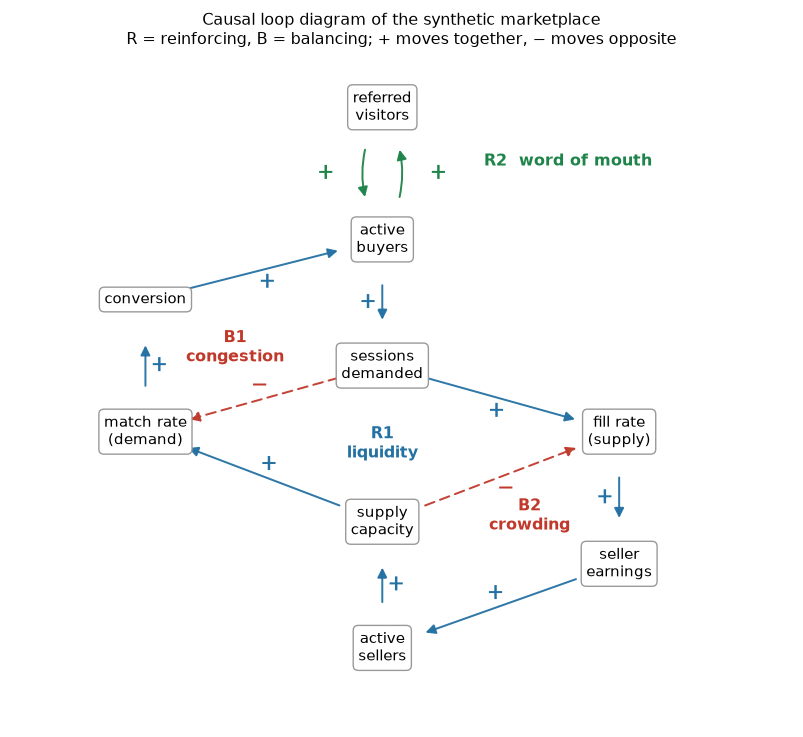

In [3]:
def cld_figure():
    nodes = {
        "active\nbuyers": (0.00, 1.65), "sessions\ndemanded": (0.00, 0.60),
        "fill rate\n(supply)": (1.85, 0.05), "seller\nearnings": (1.85, -1.05),
        "active\nsellers": (0.00, -1.75), "supply\ncapacity": (0.00, -0.70),
        "match rate\n(demand)": (-1.85, 0.05), "conversion": (-1.85, 1.15),
        "referred\nvisitors": (0.00, 2.75),
    }
    # R1 runs clockwise from the seller side back to itself
    ring = ["active\nsellers", "supply\ncapacity", "match rate\n(demand)", "conversion",
            "active\nbuyers", "sessions\ndemanded", "fill rate\n(supply)",
            "seller\nearnings", "active\nsellers"]
    # (from, to, polarity, curvature, color, line style)
    edges = [(ring[i], ring[i + 1], "+", 0.0, BLUE, "-") for i in range(8)]
    edges += [
        ("active\nbuyers", "referred\nvisitors", "+", 0.30, GREEN, "-"),
        ("referred\nvisitors", "active\nbuyers", "+", 0.30, GREEN, "-"),
        ("sessions\ndemanded", "match rate\n(demand)", "\u2212", 0.0, RED, (0, (5, 3))),
        ("supply\ncapacity", "fill rate\n(supply)", "\u2212", 0.0, RED, (0, (5, 3))),
    ]

    fig, ax = plt.subplots(figsize=(7.4, 6.8))
    for (a, b, pol, rad, color, ls) in edges:
        pa, pb = np.array(nodes[a], float), np.array(nodes[b], float)
        ax.add_patch(FancyArrowPatch(pa, pb, connectionstyle=f"arc3,rad={rad}",
                                     arrowstyle="-|>", mutation_scale=13, color=color,
                                     lw=1.3, ls=ls, shrinkA=30, shrinkB=30, alpha=0.95))
        d = pb - pa
        perp = np.array([d[1], -d[0]])
        pos = (pa + pb) / 2 + rad * perp + 0.11 * perp / np.linalg.norm(perp)
        ax.text(pos[0], pos[1], pol, color=color, fontsize=14, ha="center", va="center",
                fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.05", fc="white", ec="none"))
    for label, (x, y) in nodes.items():
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5,
                bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.6", lw=0.9))
    for text, (x, y), color in [("R1\nliquidity", (0.00, -0.05), BLUE),
                                ("R2  word of mouth", (1.45, 2.30), GREEN),
                                ("B1\ncongestion", (-1.15, 0.75), RED),
                                ("B2\ncrowding", (1.15, -0.65), RED)]:
        ax.text(x, y, text, ha="center", va="center", fontsize=10.5,
                color=color, fontweight="bold")
    ax.set_xlim(-2.9, 3.2)
    ax.set_ylim(-2.4, 3.2)
    ax.axis("off")
    ax.set_title("Causal loop diagram of the synthetic marketplace\n"
                 "R = reinforcing, B = balancing; + moves together, \u2212 moves opposite",
                 fontsize=10.5)
    plt.tight_layout()


cld_figure()

Read the figure as two sides of one market, joined by matching.

The **left column** is the buyer experience: match rate (share of requested
sessions that find a seller) feeds conversion, which feeds the stock of active
buyers. The **right column** is the seller experience: fill rate (share of
offered hours that get booked) feeds earnings, which feeds the stock of active
sellers. The **center** is the matching technology: sessions demanded versus
supply capacity. Those two quantities determine both rates at once, because
they are two views of the same matched sessions.

Start at `active sellers` and walk **clockwise**. That is loop **R1**. Extra
sellers raise supply capacity, which raises the match rate, which raises
conversion, which raises active buyers. Extra buyers raise sessions demanded,
which raises the fill rate, which raises seller earnings, which brings still
more sellers. There is no − on this path, so a small advantage on either side
compounds into a larger one. This is why a marketplace that is slightly better
at matching can pull away from one that is not, even if both start with the
same number of buyers and sellers.

The green loop at the top is **R2**. Active buyers create referred visitors,
referred visitors become active buyers. It does not go through matching. It
does, in the equations, go through reputation: referrals are stronger when the
market has recently been good at matching, and reputation adjusts slowly. That
delay is a stock in the simulation (`reputation`) and is only implicit in the
diagram.

The two **red dashed arrows** are the brakes.

**B1** is the − from `sessions demanded` to `match rate`. Hold supply fixed and
add buyers: each requested session is less likely to find a seller. Conversion
falls, churn rises, and demand growth slows. Count the − signs around that
smaller loop (buyers → sessions demanded −→ match rate → conversion → buyers)
and there is one of them, so the loop is balancing.

**B2** is the − from `supply capacity` to `fill rate`. Hold demand fixed and
add sellers: each offered hour is less likely to be booked. Earnings fall,
entry slows, churn rises, and supply growth slows. Same logic, other side.

Those two − arrows are why the blue ring cannot explode. R1 says "more of
either side helps the other." B1 and B2 say "more of one side, without the
other, hurts the first side." Growth continues only while matching can absorb
the imbalance. That is also why a promotion and a matching improvement, which
can look identical in a two-week experiment, are different policies: the first
loads B1, the second raises the gain of R1.

Two delays in the equations are easy to miss on the diagram. Sellers do not
jump from signup to active; they sit in `sellersOnboarding` for twelve weeks.
Sellers do not react to this week's earnings; they react to
`perceivedEarnings`, which trails actual earnings by about two months. Delays
inside a loop are what turn a smooth intention ("we need more supply") into
overshoot: the signal to enter is still high after the market has already
filled in.

## Where the parameters come from

This is the part that connects the two worlds, and it is the reason I think SD
belongs in a data science team rather than next to it. A stock-and-flow model is
mostly a set of behavioral response parameters, and those are exactly the
quantities a good experimentation program already estimates.

The table below is the fictional evidence base for this model. Read it as "these
are the four experiments whose results we are propagating", each with a standard
error, because we will need that uncertainty later.

| Parameter | Meaning | Fake estimate (SE) | Fictional source |
|---|---|---|---|
| `conversionSensitivity` | conversion response to match rate | 1.8 (0.35) | ranking algorithm A/B test |
| `churnSensitivity` | buyer churn response to unmet demand | 2.5 (0.60) | availability holdout study |
| `referralRate` | referred visitors per buyer per week | 0.030 (0.006) | referral program experiment |
| `churnElasticity` | seller churn response to earnings | 2.5 (0.50) | payout change rollout |

Two remarks. First, an experiment estimates a *local* response: what happens to
conversion when the match rate moves a little, around the match rate we
currently have. Using it far from that operating point is an extrapolation, and the model
makes that extrapolation explicit and criticizable rather than implicit.

Second, marketplace experiments have an interference problem that the model
helps articulate. Treated and control buyers compete for the same sellers, so a
treatment that shifts demand also shifts the match rate faced by the control
group. The experimental estimate is closest to the "partial equilibrium"
response, holding the rest of the system fixed. That is precisely the quantity a
stock-and-flow model wants as an input, and precisely why the model's output is
not the same number.

## Baseline behavior

Start the model out of balance, with too few sellers for the buyers already
present, and let it run for 500 weeks, a bit under ten years.

   week     buyers   sellers  matchRate  fillRate  sellerEarnings
  0.000  6,000.000   400.000      0.551     0.688         115.641
 50.000 11,159.925 1,141.759      0.707     0.576          96.751
100.000 14,877.159 1,496.476      0.701     0.581          97.555
150.000 17,035.160 1,705.870      0.699     0.582          97.768
200.000 18,291.324 1,827.469      0.698     0.583          97.876
250.000 19,018.790 1,897.823      0.698     0.583          97.934
300.000 19,438.938 1,938.436      0.698     0.583          97.966
350.000 19,681.217 1,961.849      0.698     0.583          97.984
400.000 19,820.801 1,975.336      0.698     0.583          97.994
450.000 19,901.178 1,983.101      0.698     0.583          98.000
500.000 19,947.448 1,987.571      0.698     0.583          98.003


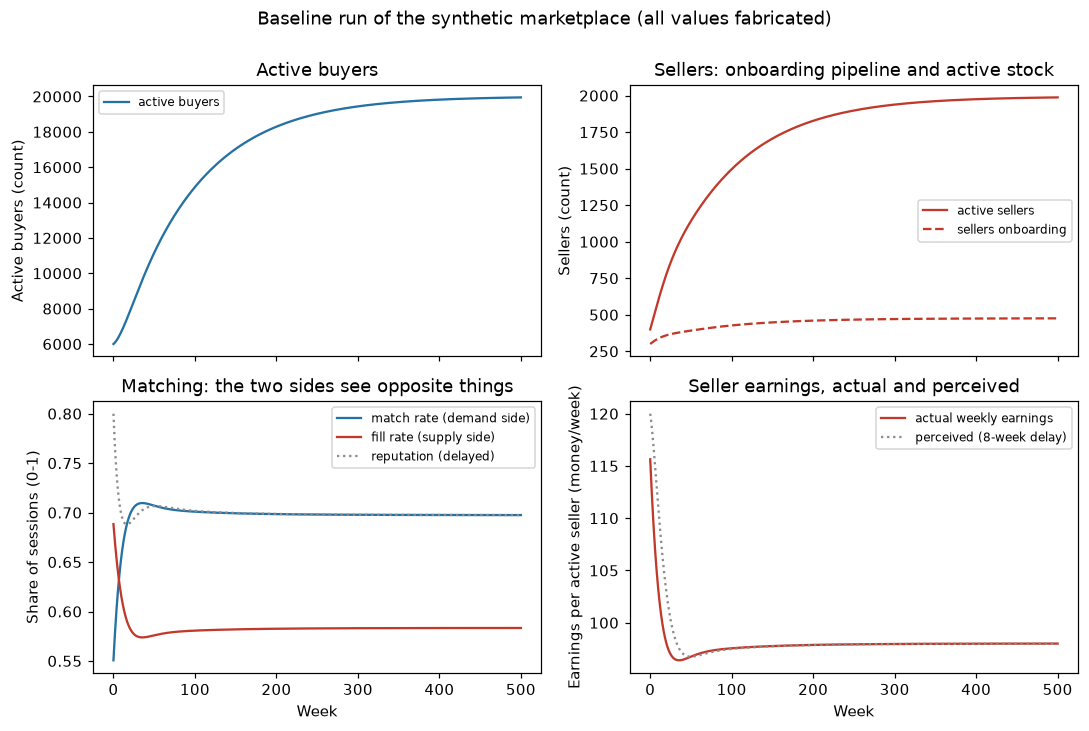

In [4]:
p = Params()
base = simulate(p)

fig, axes = plt.subplots(2, 2, figsize=(10, 6.6), sharex=True)

ax = axes[0, 0]
ax.plot(base.week, base.buyers, color=BLUE, label="active buyers")
ax.set_ylabel("Active buyers (count)")
ax.set_title("Active buyers")
ax.legend(fontsize=8)

ax = axes[0, 1]
ax.plot(base.week, base.sellers, color=RED, label="active sellers")
ax.plot(base.week, base.sellersOnboarding, color=RED, ls="--", label="sellers onboarding")
ax.set_ylabel("Sellers (count)")
ax.set_title("Sellers: onboarding pipeline and active stock")
ax.legend(fontsize=8)

ax = axes[1, 0]
ax.plot(base.week, base.matchRate, color=BLUE, label="match rate (demand side)")
ax.plot(base.week, base.fillRate, color=RED, label="fill rate (supply side)")
ax.plot(base.week, base.reputation, color=GRAY, ls=":", label="reputation (delayed)")
ax.set_ylabel("Share of sessions (0-1)")
ax.set_xlabel("Week")
ax.set_title("Matching: the two sides see opposite things")
ax.legend(fontsize=8)

ax = axes[1, 1]
ax.plot(base.week, base.sellerEarnings, color=RED, label="actual weekly earnings")
ax.plot(base.week, base.perceivedEarnings, color=GRAY, ls=":", label="perceived (8-week delay)")
ax.set_ylabel("Earnings per active seller (money/week)")
ax.set_xlabel("Week")
ax.set_title("Seller earnings, actual and perceived")
ax.legend(fontsize=8)

fig.suptitle("Baseline run of the synthetic marketplace (all values fabricated)", y=1.0)
plt.tight_layout()

print(base.iloc[::400][["week", "buyers", "sellers", "matchRate", "fillRate",
                        "sellerEarnings"]].to_string(index=False))

The baseline is not dramatic, and that is the point: nothing here is a shock, a
seasonality, or an intervention. The shape comes entirely from structure.

There are two distinct regimes, and the transition between them happens around
week 35 without anything in the model changing.

In the **adjustment phase**, the two sides experience opposite markets. Supply
was scarce at the start, so sellers pour in and the match rate climbs from 0.55
to 0.71: buyers see a market that keeps getting better at finding them someone.
The fill rate *falls* over exactly the same weeks, from 0.69 to 0.57, because
capacity is arriving faster than demand can absorb it. Sellers see a market that
keeps getting worse at filling their calendar, and their earnings drop from
about 116 to 97 a week. A dashboard built for the buyer side and a dashboard
built for the seller side would tell opposite stories about the same weeks, and
both would be right.

In the **balanced-growth phase** that follows, both rates go nearly flat, near
0.70 and 0.58, while buyers and sellers keep growing together, reaching about
19,900 and 1,990 by week 500, almost the stock equilibrium of 20,000 and 2,000.
The *ratios* find their equilibrium in the first year; the *levels* take most
of a decade. A team watching only rates would conclude the marketplace stopped
changing in year one. A team watching only counts would see slow growth all
the way to week 500.

Watch the two earnings lines in the last panel. Perceived earnings trail actual
ones by about two months, so sellers spend the entire adjustment phase entering
a market on the strength of earnings that have already gone. That gap is the
delay that the crowding loop works through, and it is why supply keeps arriving
after the calendar has stopped filling.

## Which loop is doing the work?

A stock-and-flow model earns its keep when it explains *why* a trajectory has
the shape it does. The standard move is to cut one link at a time and re-run:
if removing a loop flattens the curve, that loop was carrying the behavior.

An important caveat: cutting a loop changes the model's equilibrium, not just
its transient. These runs are diagnostics of the model's internal structure, not
forecasts of what would happen if that mechanism vanished from the real world.

                       buyers, week 500  sellers, week 500  match rate, week 500  cumulative GMV (M)  cumulative GM (M)
full model                   19,947.448          1,987.571                 0.698             120.386             31.300
no R1 liquidity              10,689.044          1,291.815                 0.765              76.800             19.968
no R2 word of mouth          13,824.241          1,541.120                 0.738              93.065             24.197
no B2 seller crowding        51,726.320          6,683.646                 0.788             270.897             70.433
no saturation                21,139.073          2,101.595                 0.697             125.277             32.572


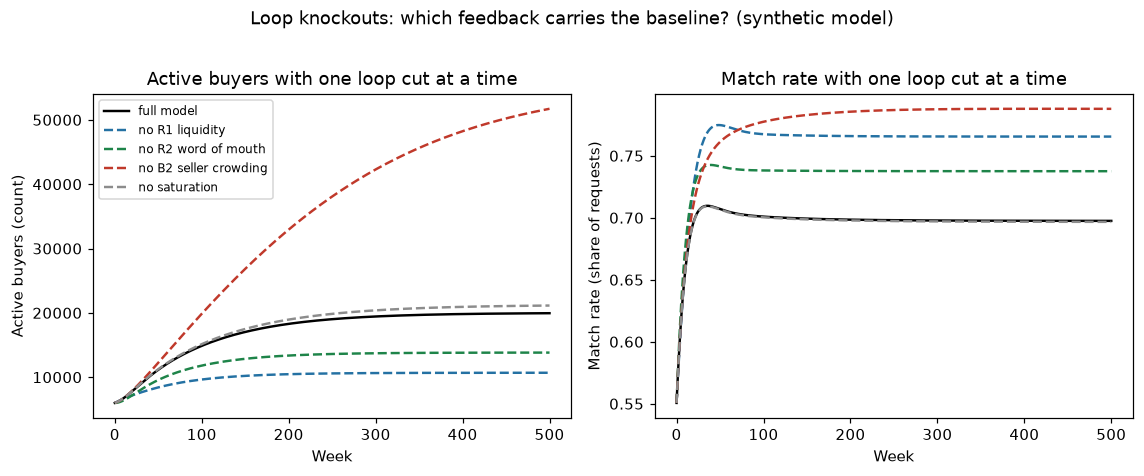

In [5]:
knockouts = {
    "full model": p,
    "no R1 liquidity": replace(p, swLiquidity=0.0),
    "no R2 word of mouth": replace(p, swWordOfMouth=0.0),
    "no B2 seller crowding": replace(p, swCrowding=0.0),
    "no saturation": replace(p, swSaturation=0.0),
}
runs = {name: simulate(q) for name, q in knockouts.items()}

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
colors = {"full model": "black", "no R1 liquidity": BLUE, "no R2 word of mouth": GREEN,
          "no B2 seller crowding": RED, "no saturation": GRAY}
for name, r in runs.items():
    style = "-" if name == "full model" else "--"
    axes[0].plot(r.week, r.buyers, style, color=colors[name], lw=1.6, label=name)
    axes[1].plot(r.week, r.matchRate, style, color=colors[name], lw=1.6, label=name)
axes[0].set_xlabel("Week"); axes[0].set_ylabel("Active buyers (count)")
axes[0].set_title("Active buyers with one loop cut at a time")
axes[1].set_xlabel("Week"); axes[1].set_ylabel("Match rate (share of requests)")
axes[1].set_title("Match rate with one loop cut at a time")
axes[0].legend(fontsize=8)
fig.suptitle("Loop knockouts: which feedback carries the baseline? (synthetic model)", y=1.02)
plt.tight_layout()

summary = pd.DataFrame({
    "buyers, week 500": {k: v.buyers.iloc[-1] for k, v in runs.items()},
    "sellers, week 500": {k: v.sellers.iloc[-1] for k, v in runs.items()},
    "match rate, week 500": {k: v.matchRate.iloc[-1] for k, v in runs.items()},
    "cumulative GMV (M)": {k: cumulative_gmv(v) / 1e6 for k, v in runs.items()},
    "cumulative GM (M)": {k: cumulative_gm(v) / 1e6 for k, v in runs.items()},
})
print(summary.to_string())

The left panel is the stock of buyers. The right panel is the match rate they
experience. The table is the same runs at week 500.

Cutting **R1 (liquidity)** does the most damage: buyers end about 46% below the
full model and GMV (and GM, the same percentage while take rate is fixed) about
36% below. Without the cross-side link from match rate
to conversion, extra sellers stop helping recruit buyers, and the market loses
the mechanism that makes it a marketplace rather than two independent funnels.
Cutting **R2 (word of mouth)** costs about 31% of buyers and 23% of GMV, and
this one is worth putting next to what channel attribution would say. In the
baseline, referred visitors grow from 22% of all visitors to 43% by week 500, so
an attribution dashboard would report, correctly, that organic referral supplies
more than 40% of the top of the funnel. The knockout says removing it costs 31%
of buyers. The dashboard number is *larger* than the loop's actual contribution.

The gap is the rest of the system responding. Attribution measures a share of a
flow with everything else held fixed, which is close to what an experiment
measures. But when referral goes away the market ends up smaller, congestion
eases, the match rate rises from 0.70 to 0.74, and conversion improves enough to
recover part of the loss. The balancing loops absorb a share of any shock, in
either direction. That is the whole argument of this post in miniature: the same
mechanism is worth 43% of traffic and 31% of the business, and only one of those
two numbers answers "what happens if we lose it".

Match rate is *higher* in both the R1 and R2 runs, for the same reason. It looks
like a quality win until you notice it is a smaller, less congested market.

Cutting **B2 (seller crowding)** does the opposite. Buyers and sellers keep
climbing, match rate keeps climbing, and GMV is more than double. That is the
diagnostic: in the full model, seller crowding is the main ceiling. New sellers
dilute earnings, entry slows, and the liquidity loop cannot compound as freely.
The extra years make this louder, because without B2 the stocks have not
equilibrated by week 500.

**No saturation** is the gray line sitting almost on top of the full model, and
that small gap is the result, not a failed run. Saturation here is not a
separate loop. It only shrinks word-of-mouth and seller-referral as the stocks
approach a finite pool (250,000 possible buyers, 25,000 possible sellers). Paid
acquisition is unaffected. At week 500 the market is still far from those
ceilings, about 19,900 buyers and 2,000 sellers, so the referral brake has
barely started. Turning it off adds only about 6% more buyers. The ceiling
that *is* binding is B2, not running out of people.

### A loop's sign depends on the operating point

One result from building this deserves more attention than it usually gets,
because I ran into it by accident when I lowered the matching efficiency.

Whether R1 reads as an engine or a drag is not a property of the loop. It
depends on where the market sits relative to `matchReference`, the match rate
buyers judge the market against. Conversion responds to `matchRate -
matchReference`, so if the market operates *below* the reference, the liquidity
channel is subtracting from conversion every week. Raise `matchReference` to
0.85 and leave everything else untouched: the market now runs below what buyers
expect, and cutting R1 sends buyers *up* by 34%, because the knockout removes a
standing penalty rather than an engine. In the calibration above, where the
market runs comfortably over its reference, the same cut sends buyers down 46%.
Same structure, same equations, opposite conclusion.

This is a real trap, and it is not confined to toy models. The reference point
is what makes the effect relative, and it is almost always the least evidenced
number in the model, since experiments measure the *slope* of a response, not
the point people compare against. If you recalibrate a matching parameter, you
have to move the reference with it or you will silently flip the sign of your
main loop and then write a confident paragraph about it.

The general lesson is Meadows': loop dominance shifts with the state of the
system. A diagram tells you which loops exist, not which one is in charge this
quarter. Only running the model tells you that.

**Taking the knockouts together.** The baseline is not an exogenous trend. It is R1 and R2 pushing
growth, pressed against B2. If a team only watches buyer conversion, it will
read the rising match rate as "the product is getting better" and miss that
sellers are getting a thinner calendar. The next section uses that structure:
two policies with the same two-week experiment result, plugged into different
loops.

## The part an A/B test cannot tell you

Now the demonstration that motivated this post. Suppose two teams each propose a
change, and each runs a clean two-week experiment.

- **Team A: a promotion.** A discount that lifts visitor-to-buyer conversion
  directly. It does nothing to the matching technology.
- **Team B: better matching.** A ranking improvement that raises matching
  efficiency $$\alpha$$, so the same supply produces more matches, which raises
  the match rate, which raises conversion.

I calibrate the promotion so that both changes produce *exactly the same
measured conversion lift* at the moment of the test. Two identical experiment
readouts, two very different pieces of machinery underneath.

In [6]:
state = base[base.week == 52.0].iloc[0]
demand = state.buyers * p.sessionsPerBuyer
capacity = state.sellers * p.sellerCapacity
match_shift = 0.15

match_of = lambda a: 1 - np.exp(-a * capacity / demand)
conv_of = lambda m: min(0.9, max(0.01, p.baseConversion * (
    1 + p.conversionSensitivity * (m - p.matchReference))))

match_before = match_of(p.matchEfficiencyBase)
match_after = match_of(p.matchEfficiencyBase + match_shift)
measured_lift = conv_of(match_after) / conv_of(match_before) - 1

print(f"matching change raises the match rate {match_before:.3f} -> {match_after:.3f} at week 52")
print(f"conversion lift a two-week A/B test would report: {100 * measured_lift:+.2f}%")
print(f"promotion calibrated to the same lift: baseConversion x {1 + measured_lift:.4f}")

promo = simulate(p, conversionMultiplier=1 + measured_lift)
match = simulate(p, matchEfficiencyShift=match_shift)

matching change raises the match rate 0.707 -> 0.756 at week 52
conversion lift a two-week A/B test would report: +7.45%
promotion calibrated to the same lift: baseConversion x 1.0745


         policy measured A/B conversion lift buyers, +1 year buyers, week 500 sellers, week 500 cumulative GMV cumulative GM
      promotion                        +7.4%           +3.6%            +6.2%             +4.3%          +4.4%         +4.4%
better matching                        +7.4%          +16.4%           +53.5%            +50.9%         +48.7%        +48.7%


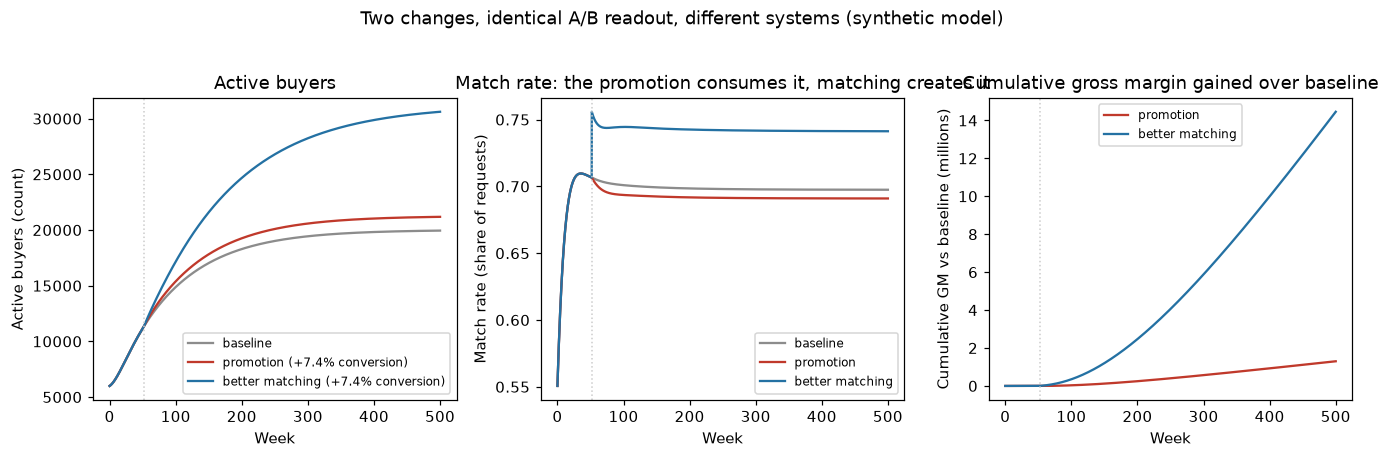

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.0))

axes[0].plot(base.week, base.buyers, color=GRAY, label="baseline")
lift_label = f"(+{100 * measured_lift:.1f}% conversion)"
axes[0].plot(promo.week, promo.buyers, color=RED, label=f"promotion {lift_label}")
axes[0].plot(match.week, match.buyers, color=BLUE, label=f"better matching {lift_label}")
axes[0].axvline(52, color="0.8", lw=1, ls=":")
axes[0].set_xlabel("Week"); axes[0].set_ylabel("Active buyers (count)")
axes[0].set_title("Active buyers")
axes[0].legend(fontsize=8)

axes[1].plot(base.week, base.matchRate, color=GRAY, label="baseline")
axes[1].plot(promo.week, promo.matchRate, color=RED, label="promotion")
axes[1].plot(match.week, match.matchRate, color=BLUE, label="better matching")
axes[1].axvline(52, color="0.8", lw=1, ls=":")
axes[1].set_xlabel("Week"); axes[1].set_ylabel("Match rate (share of requests)")
axes[1].set_title("Match rate: the promotion consumes it, matching creates it")
axes[1].legend(fontsize=8)

weeks = base.week.values
cum_gm = lambda d: np.concatenate([[0], np.cumsum(np.diff(d.week) * d.weeklyGM.values[:-1])])
axes[2].plot(weeks, (cum_gm(promo) - cum_gm(base)) / 1e6, color=RED, label="promotion")
axes[2].plot(weeks, (cum_gm(match) - cum_gm(base)) / 1e6, color=BLUE, label="better matching")
axes[2].axvline(52, color="0.8", lw=1, ls=":")
axes[2].set_xlabel("Week"); axes[2].set_ylabel("Cumulative GM vs baseline (millions)")
axes[2].set_title("Cumulative gross margin gained over baseline")
axes[2].legend(fontsize=8)

fig.suptitle("Two changes, identical A/B readout, different systems (synthetic model)", y=1.03)
plt.tight_layout()

rows = []
for name, run in [("promotion", promo), ("better matching", match)]:
    rows.append({
        "policy": name,
        "measured A/B conversion lift": f"{100 * measured_lift:+.1f}%",
        "buyers, +1 year": f"{100 * (run[run.week == 104].buyers.iloc[0] / base[base.week == 104].buyers.iloc[0] - 1):+.1f}%",
        "buyers, week 500": f"{100 * (run.buyers.iloc[-1] / base.buyers.iloc[-1] - 1):+.1f}%",
        "sellers, week 500": f"{100 * (run.sellers.iloc[-1] / base.sellers.iloc[-1] - 1):+.1f}%",
        "cumulative GMV": f"{100 * (cumulative_gmv(run, 52) / cumulative_gmv(base, 52) - 1):+.1f}%",
        "cumulative GM": f"{100 * (cumulative_gm(run, 52) / cumulative_gm(base, 52) - 1):+.1f}%",
    })
print(pd.DataFrame(rows).to_string(index=False))

Same experiment result, roughly an elevenfold difference in cumulative GM by
week 500. GMV (what buyers pay) moves in the same proportion here, because the
take rate is unchanged. When a lever changes the take rate, those two numbers
can part: that is why the model tracks both.

The mechanism is visible in the middle panel. The promotion spends the match
rate: it pulls more buyers onto a fixed pool of sellers, so the very thing that
converts buyers gets slightly worse, and loop B1 eats part of the gain. It still
helps, because a higher fill rate eventually attracts sellers, but it is
fighting its own side effect. Better matching *produces* match rate: it raises
the yield of the existing pool, which improves conversion and retention, which
raises fill rate and earnings, which brings sellers, which raises the match rate
again.
The first change nudges a flow once. The second changes the gain of loop R1, and
a change in a loop's gain compounds.

Nothing about that distinction is visible in the experiment readout, because at
the moment of measurement the two are identical by construction. It is visible
only if you write down where each change enters the structure.

## Carrying the experimental uncertainty through

The parameters came from experiments, so they have standard errors, and it would
be strange to report a single trajectory as if they did not. Propagating that
uncertainty is a Monte Carlo over parameter draws: sample each response
parameter from its (fictional) sampling distribution, run the model, repeat.

This is where the SD model starts to look like the rest of the data science
workflow. The output is not a point forecast, it is a distribution of behaviors
consistent with what the experiments actually established.

cumulative GM gain: median 48.4%, 10th-90th percentile 38.5% to 57.4%
share of draws where the gain exceeds 10%: 100%


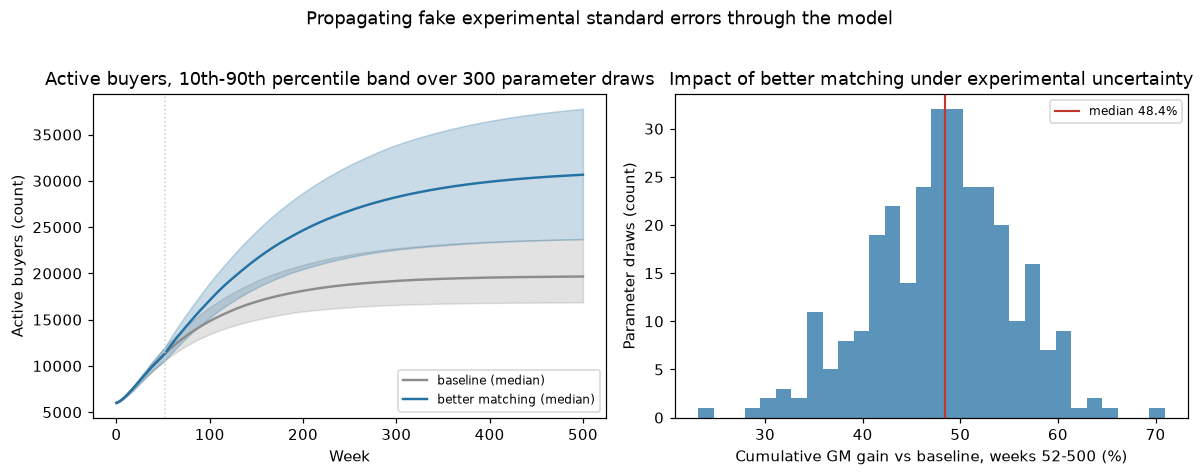

In [8]:
rng = np.random.default_rng(20260821)
n_draws = 300
draws = pd.DataFrame({
    "conversionSensitivity": rng.normal(1.8, 0.35, n_draws),
    "churnSensitivity": rng.normal(2.5, 0.60, n_draws),
    "referralRate": rng.normal(0.030, 0.006, n_draws),
    "churnElasticity": rng.normal(2.5, 0.50, n_draws),
}).clip(lower=0.001)

paths_base, paths_match, gm_gain = [], [], []
for _, d in draws.iterrows():
    q = replace(p, **d.to_dict())
    b = simulate(q)
    m = simulate(q, matchEfficiencyShift=match_shift)
    paths_base.append(b.buyers.values)
    paths_match.append(m.buyers.values)
    gm_gain.append(100 * (cumulative_gm(m, 52) / cumulative_gm(b, 52) - 1))

paths_base, paths_match = np.array(paths_base), np.array(paths_match)
gm_gain = np.array(gm_gain)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for paths, color, label in [(paths_base, GRAY, "baseline"), (paths_match, BLUE, "better matching")]:
    lo, mid, hi = np.percentile(paths, [10, 50, 90], axis=0)
    axes[0].fill_between(base.week, lo, hi, color=color, alpha=0.25)
    axes[0].plot(base.week, mid, color=color, lw=1.6, label=f"{label} (median)")
axes[0].axvline(52, color="0.8", lw=1, ls=":")
axes[0].set_xlabel("Week"); axes[0].set_ylabel("Active buyers (count)")
axes[0].set_title("Active buyers, 10th-90th percentile band over 300 parameter draws")
axes[0].legend(fontsize=8)

axes[1].hist(gm_gain, bins=30, color=BLUE, alpha=0.75)
axes[1].axvline(np.median(gm_gain), color=RED, lw=1.4,
                label=f"median {np.median(gm_gain):.1f}%")
axes[1].set_xlabel("Cumulative GM gain vs baseline, weeks 52-500 (%)")
axes[1].set_ylabel("Parameter draws (count)")
axes[1].set_title("Impact of better matching under experimental uncertainty")
axes[1].legend(fontsize=8)

fig.suptitle("Propagating fake experimental standard errors through the model", y=1.02)
plt.tight_layout()

print(f"cumulative GM gain: median {np.median(gm_gain):.1f}%, "
      f"10th-90th percentile {np.percentile(gm_gain, 10):.1f}% to {np.percentile(gm_gain, 90):.1f}%")
print(f"share of draws where the gain exceeds 10%: {100 * (gm_gain > 10).mean():.0f}%")

The conclusion survives the entire parameter cloud. Every draw puts the GM gain
from better matching well above the promotion calibrated to the identical
experiment readout. The two do not come close to overlapping anywhere in the
sampled space, so the ranking of the two policies does not depend on getting the
response parameters right, only on having them in the right neighborhood.

That is worth separating from a forecast. I would not defend the median as a number.
I would defend "the matching change dominates the promotion by roughly an order
of magnitude, and no plausible combination of these four parameters reverses
it", which is a claim about structure rather than magnitude, and it is the kind
of claim that survives contact with reality more often. The band is also a
reading list for the next experiment: its width comes from response parameters
that could be measured better, and the model says which ones would narrow it.

## Why build this in AnyLogic

Everything above is 60 lines of Python, so why bother with a simulation
platform? Because the Python is a good *analysis* environment and a poor
*communication* one. The equations are readable to me and opaque to almost
everyone whose decision the model is supposed to inform.

In AnyLogic the same model is a stock-and-flow diagram: stocks are boxes, flows
are pipes with valves, and causal links are arrows you can trace with a finger.
When a stakeholder disagrees with the model, they point at an arrow. That is a
much better conversation than one about a for loop, and it is the reason the SD
tradition has always been diagram-first.

The model in this post is available as a small AnyLogic file:
[marketplace_sd.alp](/assets/files/marketplace_sd.alp). It has 6 stocks, 8
flows, 15 auxiliary variables, and 32 parameters, and it is generated by a
[script](https://github.com/sdaza/sdaza.github.io/blob/master/_scripts/make_anylogic_sd.py).

I originally wrote here that generating the file from a script meant the
AnyLogic equations and the Python equations *could not* drift apart. That was
wrong, and it is worth correcting rather than quietly fixing, because the
failure is a common one. Generation guarantees that the file is produced
mechanically. It does not guarantee that the thing being produced still matches
a second implementation maintained by hand a directory away. When I lowered the
matching efficiency and added the loop switches, I changed the notebook and not
the generator, and for a while the AnyLogic model silently had no switches in it
at all. Every knockout in this post was unreproducible in the diagram I was
telling people to trust.

Two implementations of the same equations do not stay in sync because you intend
them to. They stay in sync because something fails when they diverge. So there
is now a
[reader](https://github.com/sdaza/sdaza.github.io/blob/master/_scripts/alp_model.py)
that parses the `.alp`, translates its Java expressions to Python, and
integrates them with the same Euler scheme, and a
[runner](https://github.com/sdaza/sdaza.github.io/blob/master/_scripts/run_experiments.py)
that executes every scenario in this post through both and compares the
trajectories. They currently agree exactly.

On its own that checks the equations and parameter values stored in the file
rather than AnyLogic's own solver. So the runner also picks up whatever the
AnyLogic experiments have actually written to `experiments/`, and compares those
runs too. Run a scenario in AnyLogic and the comparison covers the real thing;
skip it and the weaker check still holds.

Two settings matter for reproducing the numbers. The model uses **Euler
integration with a fixed step of 0.125 week**, and time is measured in weeks.

Every counterfactual in this post is a parameter change rather than a code
change. That is a deliberate constraint, and it is what makes the model usable
by someone who does not write Python: the loop knockouts are `swLiquidity`,
`swWordOfMouth`, `swCrowding` and `swSaturation`, each 1 to keep a loop and 0 to
cut it, and the policies are `matchEfficiencyShift`, `conversionMultiplier`,
`paidVisitorMultiplier`, `policyStart` and `policyStop`.

Because a scenario is nothing but a set of numbers, each one ships as its own
experiment. Opening the `.alp` shows 18 of them in the project tree, named for
the scenarios discussed above: `baseline`, `no_R1_liquidity`, `no_B2_crowding`,
`promotion`, `better_matching`, `matching_start_208`, `reference_085`, and so
on. Each already carries its parameter values, so reproducing a counterfactual
is a double-click rather than a setup exercise, and the diagram is identical
across all of them. When a run finishes it writes its weekly series to
`experiments/<scenario>.csv` next to the model file.

That last part is worth a note, because "export the results" is usually where
the diagram-first workflow falls apart. AnyLogic can create a dataset for every
stock, flow and auxiliary automatically, which the model turns on; the
experiments then walk those datasets after the run and write them out. Nobody
has to remember which series to tick before clicking run.

## When this is worth doing, and when it is not

A stock-and-flow model is worth building when the question is about behavior
over time in a system that feeds back on itself: two-sided marketplaces,
capacity and backlog, retention with word of mouth, workforce pipelines,
anything with an onboarding delay. It is also worth building when a team keeps
having the same argument, because the model turns a disagreement about
narratives into a disagreement about a specific arrow or parameter.

It is the wrong tool when the question is genuinely about individual
heterogeneity or network structure. SD works with aggregates, so if the answer
depends on *who* is connected to whom, agent-based modeling is the better
choice, and AnyLogic will let you mix the two in the same model.

Some things I try to keep in mind:

**A model is not a forecast.** Its output is a set of behavior modes, and its
value is the argument about structure, not the number in year ten. I try to
present ranges and, where possible, the sign rather than the magnitude.

**Calibrate what you can, and be explicit about the rest.** The response
parameters here are exactly the sort of quantity an experimentation program
produces. Where no experiment exists, the parameter is an assumption, and it
should be labeled as such and swept in sensitivity analysis.

**Structure beats parameter precision.** In the comparison above, the difference
between the two policies came from *where* they entered the loops, not from
finely tuned coefficients, and it survived the entire Monte Carlo cloud.

**Watch the leverage points.** Meadows' hierarchy is a useful discipline:
changing a flow rate (a promotion) is a weak intervention, changing the gain of
a feedback loop (matching quality) is a stronger one, and changing the structure
or goals of the system is stronger still.

## A closing reflection

In my experience, I have not seen companies doing this kind of modeling. Teams
run experiments, ship winners, and still argue about why the marketplace moved
the way it did, because the causal estimate is local and the system is not.
That is not a criticism of experiments. It is a description of what they leave
open.

Something similar happened with causality. For a long time it lived mostly in
econometrics and epidemiology. Then the combination of A/B testing at scale,
better language for identification, and a few stubborn questions that
correlations could not answer made it ordinary. Formal models of dynamics feel
to me like they are in that earlier place: available, underused, and easy to
dismiss as too theoretical until a decision depends on a loop rather than on a
two-week lift.

I do not think every data science team needs a stock-and-flow diagram. I do
think the next time a promotion and a matching change report the same experiment
result, it is worth asking which loop each one entered, and what that implies a
year later. The tools are already on the table. Using them together is the part
that is still rare.

## References

- Donella Meadows, *Thinking in Systems: A Primer* (2008). The clearest
  introduction to stocks, flows, loop dominance, delays, and leverage points.
- John Sterman, *Business Dynamics: Systems Thinking and Modeling for a Complex
  World* (2000). The reference textbook, including model testing and
  calibration.
- Jay Forrester, *Industrial Dynamics* (1961). Where the whole thing starts.